<a href="https://colab.research.google.com/github/zbnisa12-maker/week1_lab-/blob/main/NN_SGD_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab: Neural Network with Stochastic Gradient Descent and Backpropagation

**Course:** CSE206 Fundamental of Machine Learning
**Institution:** Amity University Tashkent
**Duration:** 2 hours (two 1-hour sessions)

| Session | Time | Content |
|---|---|---|
| Session 1 | 60 min | **Part A: Guided walkthrough.** We build a small neural network from scratch, step by step. |
| Session 2 | 60 min | **Part B: Graded exercises (100 marks).** Three exercises you complete on your own (about 30 minutes). |

### Task of this lab
We will build a neural network **from scratch** (only NumPy, no deep learning library) and train it with
**stochastic gradient descent (SGD)** and **backpropagation** to predict a **target variable** from a real dataset.

### Learning outcomes
By the end of this lab you should be able to:

1. Explain what a single neuron computes (weighted sum, bias, activation).
2. Run a **forward pass** through a network with one hidden layer.
3. Measure the error of a prediction with a **loss function**.
4. Explain the idea of **gradient descent** and the role of the **learning rate**.
5. Compute gradients with **backpropagation** and update the weights with **SGD**.
6. Train the network, plot the loss curve, and evaluate the predictions.

---
# PART A: Guided Walkthrough (Session 1)

## A.1 Import the libraries

| Library | What we use it for |
|---|---|
| `numpy` | Working with arrays of numbers (vectors and matrices) |
| `pandas` | Looking at the dataset as a table |
| `matplotlib` | Drawing plots |
| `sklearn` | Only to **load** the dataset and **split** it into train and test parts |

The neural network itself will be written by us, by hand.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

np.random.seed(42)   # fixes the random numbers, so everyone gets the same results
print("Libraries loaded.")

Libraries loaded.


## A.2 The dataset: Diabetes progression

The **Diabetes dataset** contains medical data for **442 patients**.
For every patient we have 10 measurements taken at the start of a study:

| Column | Meaning |
|---|---|
| `age` | Age of the patient |
| `sex` | Sex of the patient |
| `bmi` | Body mass index (weight relative to height) |
| `bp` | Average blood pressure |
| `s1` to `s6` | Six blood test measurements |

The **target** column is a number that measures **how much the disease progressed one year later**.
Larger number means the disease became worse.

**Our goal:** use the 10 measurements (inputs) to **predict the target** (output).
Because the target is a number (not a category), this is a **regression** problem.

Note: the creators of the dataset have already **scaled** the 10 input columns, so they are small numbers around 0.
This is good for neural networks.

In [9]:
data = load_diabetes(as_frame=True)
df = data.frame          # a table: 10 input columns + 1 "target" column

print("Number of patients (rows):", df.shape[0])
print("Number of columns        :", df.shape[1])
df.head()

Number of patients (rows): 442
Number of columns        : 11


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [10]:
print("Smallest target value:", df["target"].min())
print("Largest target value :", df["target"].max())
print("Average target value :", round(df["target"].mean(), 1))

Smallest target value: 25.0
Largest target value : 346.0
Average target value : 152.1


Let us look at one input column against the target.

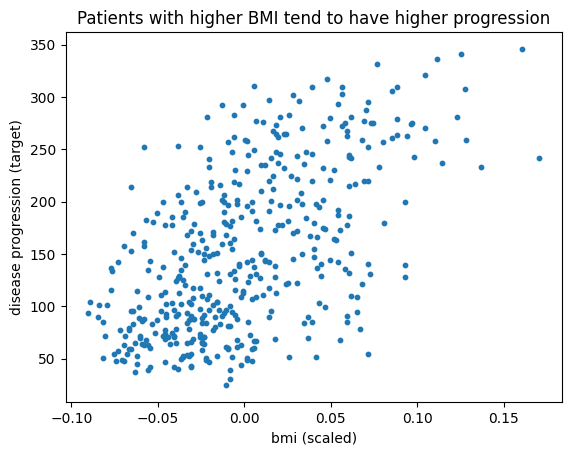

In [11]:
plt.scatter(df["bmi"], df["target"], s=10)
plt.xlabel("bmi (scaled)")
plt.ylabel("disease progression (target)")
plt.title("Patients with higher BMI tend to have higher progression")
plt.show()

The points go **up and to the right**: there is a relationship, but it is noisy.
A neural network can combine **all 10 inputs together** to make a better prediction than any single column.

## A.3 Prepare the data

We need two things:

- `X`: the inputs, a table with 442 rows and 10 columns
- `y`: the output we want to predict, a list of 442 numbers

Then we **split** the data:

- **Training set (80%)**: the network learns from these patients.
- **Test set (20%)**: patients the network has **never seen**. We use them to check if the network really learned.

In [34]:
X = df.drop(columns="target").values   # inputs
y = df["target"].values                # output (target)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape, "  y_train shape:", y_train.shape)
print("X_test  shape:", X_test.shape,  "  y_test  shape:", y_test.shape)

X_train shape: (353, 10)   y_train shape: (353,)
X_test  shape: (89, 10)   y_test  shape: (89,)


### Scaling the target

The inputs are small numbers, but the target is large (between 25 and 346).
A new network starts by predicting numbers close to 0, so the first errors would be huge (around 150),
and the weight updates would also be huge. Training becomes unstable.

The fix is to **standardise** the target:

$$y_{scaled} = \frac{y - \text{mean}}{\text{std}}$$

After this, the target has mean 0 and standard deviation 1.
We compute the mean and std from the **training set only** (the test set must stay unseen).
At the end we convert predictions back to the original units with:

$$y = y_{scaled} \times \text{std} + \text{mean}$$

In [35]:
y_mean = y_train.mean()
y_std = y_train.std()

y_train_s = (y_train - y_mean) / y_std    # "_s" means "scaled"
y_test_s = (y_test - y_mean) / y_std

print("Mean of y_train:", round(y_mean, 2), "   Std of y_train:", round(y_std, 2))
print("First 5 original targets:", y_train[:5])
print("First 5 scaled targets  :", np.round(y_train_s[:5], 2))

Mean of y_train: 153.74    Std of y_train: 77.95
First 5 original targets: [144. 150. 280. 125.  59.]
First 5 scaled targets  : [-0.12 -0.05  1.62 -0.37 -1.22]


## A.4 One neuron

A neural network is built from small units called **neurons**. One neuron does two things:

1. **Weighted sum:** multiply each input by its weight, add them up, and add a bias.

$$z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b$$

2. **Activation:** pass $z$ through a function $f$ to get the output $a = f(z)$.

The **weights** $w$ and the **bias** $b$ are the numbers the network **learns** during training.

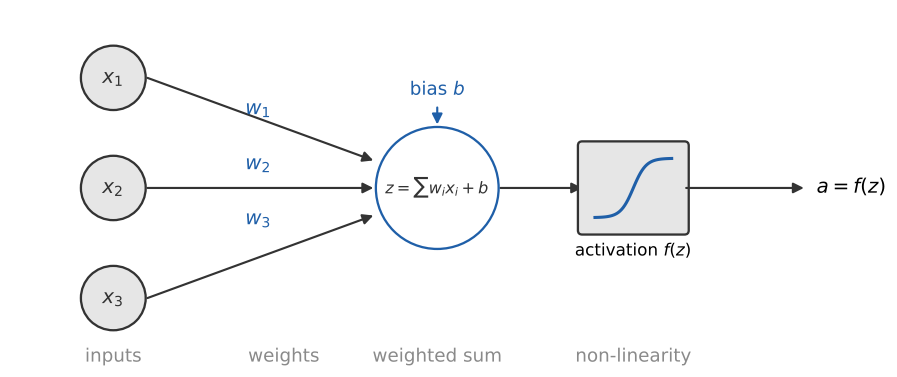

Let us compute the weighted sum for one neuron with 3 inputs.
`np.dot(w, x)` multiplies matching elements and adds them: $w_1 x_1 + w_2 x_2 + w_3 x_3$.

In [36]:
x = np.array([0.5, -1.0, 2.0])    # 3 inputs
w = np.array([0.4, 0.3, -0.2])    # 3 weights (one for each input)
b = 0.1                           # bias

# By hand: 0.4*0.5 + 0.3*(-1.0) + (-0.2)*2.0 + 0.1
z_by_hand = 0.4*0.5 + 0.3*(-1.0) + (-0.2)*2.0 + 0.1

# With NumPy
z = np.dot(w, x) + b

print("z by hand  :", round(z_by_hand, 4))
print("z by NumPy :", round(z, 4))

z by hand  : -0.4
z by NumPy : -0.4


## A.5 The activation function: sigmoid

Without an activation function, a network is only a big **linear** formula and can only learn straight-line patterns.
The activation function adds **non-linearity**, so the network can learn curved patterns.

We use the **sigmoid** function. It squeezes any number into the range 0 to 1:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

For backpropagation we also need its **derivative** (slope). It has a very simple form:

$$\sigma'(z) = a \,(1 - a), \quad \text{where } a = \sigma(z)$$

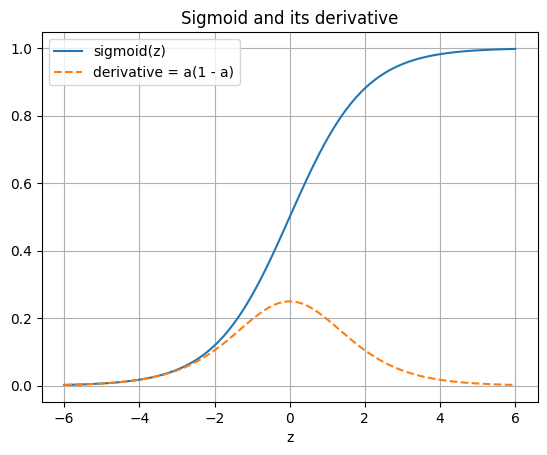

sigmoid(-0.4) = 0.4013   <- output of our neuron from A.4


In [37]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_values = np.linspace(-6, 6, 100)       # 100 numbers from -6 to 6
a_values = sigmoid(z_values)
slope = a_values * (1 - a_values)        # derivative of sigmoid

plt.plot(z_values, a_values, label="sigmoid(z)")
plt.plot(z_values, slope, label="derivative = a(1 - a)", linestyle="--")
plt.xlabel("z")
plt.legend()
plt.grid(True)
plt.title("Sigmoid and its derivative")
plt.show()

print("sigmoid(-0.4) =", round(sigmoid(-0.4), 4), "  <- output of our neuron from A.4")

Notice: the derivative is largest at $z = 0$ (value 0.25) and almost 0 for very large or very small $z$.

## A.6 Our network: 10 inputs, 8 hidden neurons, 1 output

We connect many neurons in **layers**:

- **Input layer:** the 10 measurements of one patient.
- **Hidden layer:** 8 neurons, each one looks at all 10 inputs and uses sigmoid.
- **Output layer:** 1 neuron that gives the prediction $\hat{y}$ (read "y-hat").
  It has **no activation**, because the prediction can be any number (also negative after scaling).

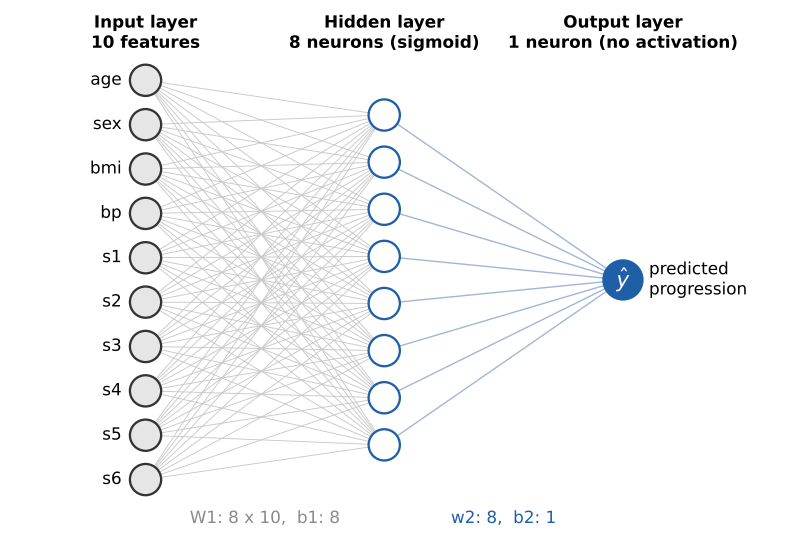

### The weights we must learn

| Name | Shape | Meaning |
|---|---|---|
| `W1` | (8, 10) | Row $j$ holds the 10 weights of hidden neuron $j$ |
| `b1` | (8,) | One bias for each hidden neuron |
| `w2` | (8,) | One weight from each hidden neuron to the output |
| `b2` | a single number | Bias of the output neuron |

Total: $8 \times 10 + 8 + 8 + 1 = 97$ numbers to learn.

We start with **small random** weights. (If all weights were the same, all hidden neurons would learn the same thing.)

In [38]:
def init_weights(n_inputs, n_hidden):
    W1 = np.random.randn(n_hidden, n_inputs) * 0.5   # small random numbers
    b1 = np.zeros(n_hidden)                          # biases start at 0
    w2 = np.random.randn(n_hidden) * 0.5
    b2 = 0.0
    return W1, b1, w2, b2

W1, b1, w2, b2 = init_weights(n_inputs=10, n_hidden=8)

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("w2 shape:", w2.shape)
print("b2      :", b2)

W1 shape: (8, 10)
b1 shape: (8,)
w2 shape: (8,)
b2      : 0.0


## A.7 Forward pass: from inputs to prediction

The **forward pass** computes the prediction for one patient, layer by layer:

$$z_1 = W_1 x + b_1 \qquad \text{(8 weighted sums)}$$

$$a_1 = \sigma(z_1) \qquad \text{(8 hidden outputs)}$$

$$\hat{y} = w_2 \cdot a_1 + b_2 \qquad \text{(1 prediction)}$$

`np.dot(W1, x)` multiplies the (8, 10) matrix by the 10 inputs and gives 8 numbers, one weighted sum for each hidden neuron.

In [39]:
def forward(x, W1, b1, w2, b2):
    z1 = np.dot(W1, x) + b1        # 8 weighted sums
    a1 = sigmoid(z1)               # 8 hidden outputs (between 0 and 1)
    y_hat = np.dot(w2, a1) + b2    # 1 number: the prediction
    return a1, y_hat

# Try it on the first training patient
x0 = X_train[0]
y0 = y_train_s[0]

a1, y_hat = forward(x0, W1, b1, w2, b2)

print("Hidden outputs a1:", np.round(a1, 3))
print("Prediction y_hat :", round(y_hat, 4))
print("True value y     :", round(y0, 4))

Hidden outputs a1: [0.507 0.472 0.505 0.481 0.503 0.518 0.502 0.517]
Prediction y_hat : 0.2592
True value y     : -0.1249


The weights are random, so the prediction is not good yet. Now we need a way to **measure** how wrong it is.

## A.8 The loss function: how wrong is the prediction?

For one patient we use the **squared error**:

$$L = \frac{1}{2}\,(\hat{y} - y)^2$$

- If the prediction is perfect, $L = 0$.
- The bigger the mistake, the bigger $L$. Squaring makes the loss always positive and punishes big mistakes more.
- The $\frac{1}{2}$ is only there to make the derivative simpler: $\dfrac{dL}{d\hat{y}} = \hat{y} - y$.

**Training = changing the weights so that the loss becomes small.**

In [40]:
def loss_fn(y_hat, y):
    return 0.5 * (y_hat - y) ** 2

print("Loss for the first patient:", round(loss_fn(y_hat, y0), 4))

Loss for the first patient: 0.0738


## A.9 Gradient descent: walking downhill

Imagine you are on a hill in thick fog and want to reach the bottom.
You cannot see the valley, but you can feel the **slope** under your feet.
So you take a small step in the **downhill** direction, and repeat.

In machine learning:

- the "hill" is the **loss**,
- your position is the value of the **weights**,
- the slope is the **gradient** $\dfrac{\partial L}{\partial w}$ (it tells how the loss changes if the weight changes a little).

**Update rule** (for every weight):

$$w_{new} = w_{old} - \eta \cdot \frac{\partial L}{\partial w}$$

$\eta$ (read "eta") is the **learning rate**: the size of each step.

- If the slope is positive, the weight goes **down**. If the slope is negative, the weight goes **up**. Either way, we move downhill.

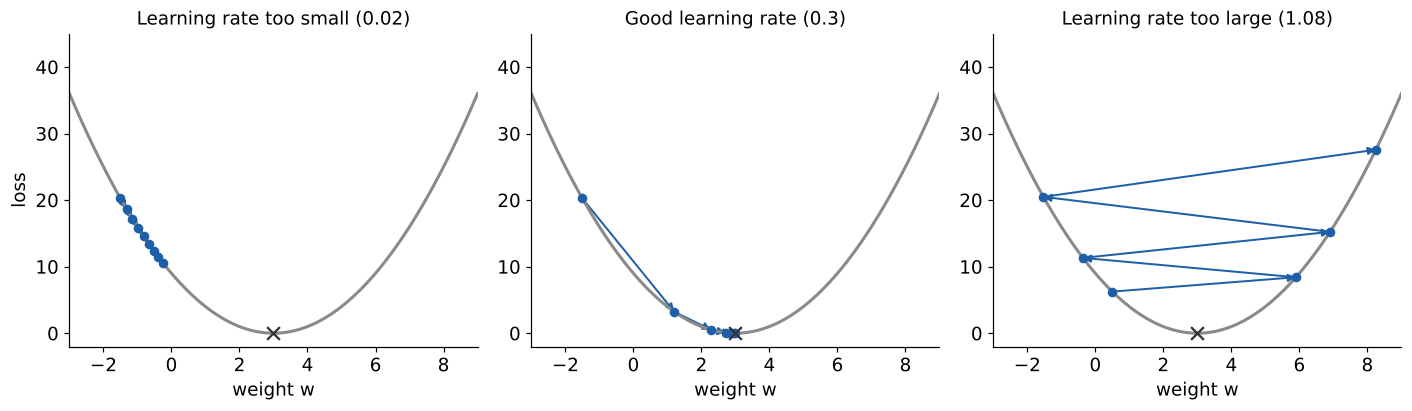

- **Too small:** many tiny steps, very slow.
- **Good:** reaches the bottom quickly.
- **Too large:** jumps over the bottom, and the loss can even grow.

### Small example with one weight

Let the loss be $L(w) = (w - 3)^2$. The best weight is clearly $w = 3$.
The gradient is $\dfrac{dL}{dw} = 2(w - 3)$. We start at $w = -1.5$ and see whether gradient descent finds 3.

In [41]:
w = -1.5              # starting weight
learning_rate = 0.3

for step in range(8):
    gradient = 2 * (w - 3)                 # slope at the current w
    w = w - learning_rate * gradient       # step downhill
    loss = (w - 3) ** 2
    print("step", step + 1, "  w =", round(w, 4), "  loss =", round(loss, 4))

step 1   w = 1.2   loss = 3.24
step 2   w = 2.28   loss = 0.5184
step 3   w = 2.712   loss = 0.0829
step 4   w = 2.8848   loss = 0.0133
step 5   w = 2.9539   loss = 0.0021
step 6   w = 2.9816   loss = 0.0003
step 7   w = 2.9926   loss = 0.0001
step 8   w = 2.9971   loss = 0.0


The weight moves towards 3 and the loss moves towards 0. A neural network does exactly this, but for **97 weights at the same time**.

**Try it live:** change `learning_rate` to `0.02` and to `1.08` and run the cell again.

## A.10 Stochastic gradient descent (SGD)

There are two common ways to use gradient descent:

| Method | How many examples for one update? | Behaviour |
|---|---|---|
| **Batch gradient descent** | **All** training examples | Smooth, but one update is slow on big datasets |
| **Stochastic gradient descent (SGD)** | **One** example (chosen randomly) | Noisy, but very many quick updates |

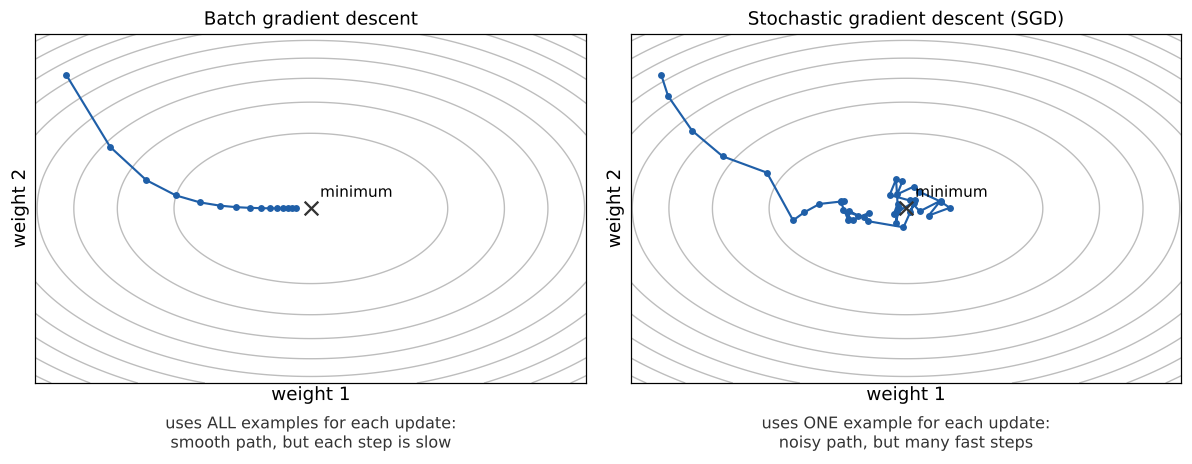

In this lab we use **SGD**:

1. **Shuffle** the training patients (a new random order).
2. For **each patient**: forward pass, compute loss, compute gradients, update the weights.
3. One full pass over all training patients is called **one epoch**. Repeat for many epochs.

The path of SGD is noisy, but on average it still goes downhill.

## A.11 Backpropagation: computing the gradients

To update the weights we need the gradient of the loss with respect to **every** weight.
**Backpropagation** computes all of them efficiently by going **backwards** through the network,
using the **chain rule** from calculus:

> If the loss depends on $\hat{y}$, and $\hat{y}$ depends on $a_1$, then
> (effect of $a_1$ on $L$) = (effect of $a_1$ on $\hat{y}$) $\times$ (effect of $\hat{y}$ on $L$).

In simple words: the error at the output is passed back, layer by layer, and each weight receives its share of the blame.

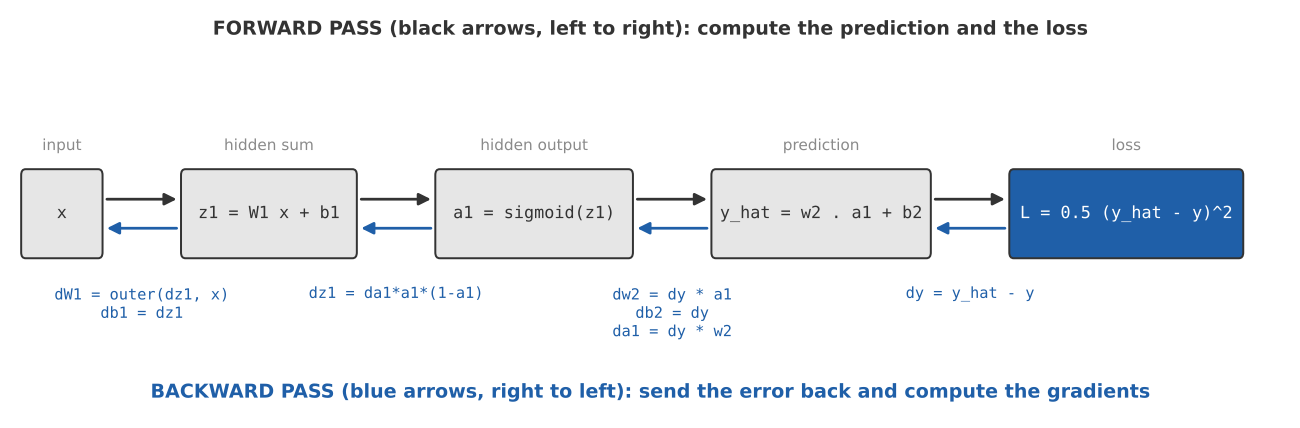

### The backward steps (read from the output to the input)

We write `dy` for $\dfrac{\partial L}{\partial \hat{y}}$, `dw2` for $\dfrac{\partial L}{\partial w_2}$, and so on.

| Step | Formula | Why |
|---|---|---|
| 1. Output error | `dy = y_hat - y` | derivative of $\frac{1}{2}(\hat{y} - y)^2$ |
| 2. Output weights | `dw2 = dy * a1` | $\hat{y} = w_2 \cdot a_1 + b_2$, so each $w_2$ is multiplied by its $a_1$ |
| 3. Output bias | `db2 = dy` | the bias is just added, so its derivative is 1 |
| 4. Error at hidden outputs | `da1 = dy * w2` | each hidden output affects $\hat{y}$ through its weight $w_2$ |
| 5. Error before sigmoid | `dz1 = da1 * a1 * (1 - a1)` | multiply by the sigmoid derivative $a(1-a)$ |
| 6. Hidden weights | `dW1 = np.outer(dz1, x)` | weight $W_1[j, i]$ connects input $i$ to neuron $j$, so its gradient is `dz1[j] * x[i]` |
| 7. Hidden biases | `db1 = dz1` | again, biases are just added |

Every gradient has the **same shape** as its weight: `dW1` is (8, 10), `db1` is (8,), `dw2` is (8,), `db2` is one number.

### What does `np.outer` do?

`np.outer(a, b)` makes a table where entry `[j, i]` is `a[j] * b[i]`. Small example:

In [42]:
a = np.array([1, 2])
b = np.array([10, 20, 30])
print(np.outer(a, b))
# row 0: 1*10, 1*20, 1*30
# row 1: 2*10, 2*20, 2*30

[[10 20 30]
 [20 40 60]]


In [43]:
def backward(x, y, a1, y_hat, w2):
    dy = y_hat - y                    # 1. error at the output
    dw2 = dy * a1                     # 2. gradient for output weights
    db2 = dy                          # 3. gradient for output bias
    da1 = dy * w2                     # 4. error sent back to the hidden outputs
    dz1 = da1 * a1 * (1 - a1)         # 5. through the sigmoid
    dW1 = np.outer(dz1, x)            # 6. gradient for hidden weights
    db1 = dz1                         # 7. gradient for hidden biases
    return dW1, db1, dw2, db2

dW1, db1, dw2, db2 = backward(x0, y0, a1, y_hat, w2)

print("dW1 shape:", dW1.shape, "  (same as W1:", W1.shape, ")")
print("db1 shape:", db1.shape, "     (same as b1:", b1.shape, ")")
print("dw2 shape:", dw2.shape, "     (same as w2:", w2.shape, ")")
print("db2      :", round(db2, 4))

dW1 shape: (8, 10)   (same as W1: (8, 10) )
db1 shape: (8,)      (same as b1: (8,) )
dw2 shape: (8,)      (same as w2: (8,) )
db2      : 0.3841


## A.12 One SGD step on one patient

Now we put everything together for **one** patient and check that the loss really goes down after one update.

In [44]:
learning_rate = 0.1

# 1. Forward pass and loss BEFORE the update
a1, y_hat = forward(x0, W1, b1, w2, b2)
loss_before = loss_fn(y_hat, y0)

# 2. Backward pass: gradients
dW1, db1, dw2, db2 = backward(x0, y0, a1, y_hat, w2)

# 3. SGD update: weight = weight - learning_rate * gradient
W1 = W1 - learning_rate * dW1
b1 = b1 - learning_rate * db1
w2 = w2 - learning_rate * dw2
b2 = b2 - learning_rate * db2

# 4. Forward pass and loss AFTER the update
a1, y_hat = forward(x0, W1, b1, w2, b2)
loss_after = loss_fn(y_hat, y0)

print("Loss before the update:", round(loss_before, 4))
print("Loss after the update :", round(loss_after, 4))

Loss before the update: 0.0738
Loss after the update : 0.0354


The loss went down. Training is simply **repeating this step** for every patient, for many epochs.

## A.13 The full training loop

We put the whole procedure into one function, `train_network`. Read the comments, they follow the SGD recipe from A.10.

We also write two helper functions:

- `predict(X, ...)`: makes a prediction for every row of `X`.
- `average_loss(X, y, ...)`: the mean loss over many patients (used to track progress after each epoch).

In [45]:
def predict(X, W1, b1, w2, b2):
    predictions = []
    for i in range(len(X)):
        a1, y_hat = forward(X[i], W1, b1, w2, b2)
        predictions.append(y_hat)
    return np.array(predictions)


def average_loss(X, y, W1, b1, w2, b2):
    y_pred = predict(X, W1, b1, w2, b2)
    return np.mean(0.5 * (y_pred - y) ** 2)


def train_network(X_train, y_train, X_test, y_test, n_hidden=8, learning_rate=0.01, epochs=50):
    np.random.seed(0)                       # same starting weights every time
    n_inputs = X_train.shape[1]
    W1, b1, w2, b2 = init_weights(n_inputs, n_hidden)

    train_losses = []                       # average training loss after each epoch
    test_losses = []                        # average test loss after each epoch

    for epoch in range(epochs):
        order = np.random.permutation(len(X_train))   # 1. shuffle the patients

        for i in order:                               # 2. one patient at a time
            x = X_train[i]
            y = y_train[i]

            a1, y_hat = forward(x, W1, b1, w2, b2)            # forward pass
            dW1, db1, dw2, db2 = backward(x, y, a1, y_hat, w2)  # backward pass

            W1 = W1 - learning_rate * dW1                     # SGD update
            b1 = b1 - learning_rate * db1
            w2 = w2 - learning_rate * dw2
            b2 = b2 - learning_rate * db2

        # 3. end of one epoch: record the losses
        train_losses.append(average_loss(X_train, y_train, W1, b1, w2, b2))
        test_losses.append(average_loss(X_test, y_test, W1, b1, w2, b2))

        if (epoch + 1) % 10 == 0:
            print("Epoch", epoch + 1, "  train loss =", round(train_losses[-1], 4),
                  "  test loss =", round(test_losses[-1], 4))

    return W1, b1, w2, b2, train_losses, test_losses

Now train the network: 8 hidden neurons, learning rate 0.01, 100 epochs.
This takes a few seconds.

In [46]:
W1, b1, w2, b2, train_losses, test_losses = train_network(
    X_train, y_train_s, X_test, y_test_s,
    n_hidden=8, learning_rate=0.01, epochs=100
)

Epoch 10   train loss = 0.4783   test loss = 0.4164
Epoch 20   train loss = 0.434   test loss = 0.3833
Epoch 30   train loss = 0.3738   test loss = 0.3208
Epoch 40   train loss = 0.313   test loss = 0.2737
Epoch 50   train loss = 0.2806   test loss = 0.2491
Epoch 60   train loss = 0.2962   test loss = 0.274
Epoch 70   train loss = 0.2596   test loss = 0.2418
Epoch 80   train loss = 0.2552   test loss = 0.236
Epoch 90   train loss = 0.2577   test loss = 0.239
Epoch 100   train loss = 0.2435   test loss = 0.2327


## A.14 The loss curve

A **loss curve** shows the loss after each epoch.

- Both curves should go **down**: the network is learning.
- If the training loss keeps going down but the test loss goes **up**, the network is memorising the training patients (**overfitting**).

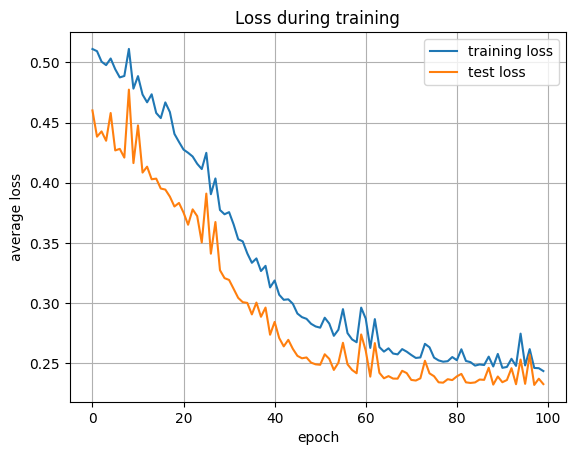

In [47]:
plt.plot(train_losses, label="training loss")
plt.plot(test_losses, label="test loss")
plt.xlabel("epoch")
plt.ylabel("average loss")
plt.title("Loss during training")
plt.legend()
plt.grid(True)
plt.show()

## A.15 Evaluate the predictions

We make predictions for the **test** patients and convert them back to the original units.

We measure the error with the **Mean Absolute Error (MAE)**: on average, how far is the prediction from the true value?

$$MAE = \frac{1}{n} \sum |\hat{y} - y|$$

To know if our MAE is good, we compare with a **baseline** that always predicts the average target of the training set.
A useful model must beat this baseline.

In [48]:
y_pred_s = predict(X_test, W1, b1, w2, b2)     # predictions (scaled)
y_pred = y_pred_s * y_std + y_mean             # back to original units

mae_network = np.mean(np.abs(y_pred - y_test))
mae_baseline = np.mean(np.abs(y_mean - y_test))

print("MAE of our neural network      :", round(mae_network, 1))
print("MAE of baseline (always mean)  :", round(mae_baseline, 1))

MAE of our neural network      : 42.8
MAE of baseline (always mean)  : 64.0


In [49]:
results = pd.DataFrame({
    "true value": y_test[:8],
    "prediction": np.round(y_pred[:8], 1)
})
results

,true value,prediction
0,219.0,145.6
1,70.0,169.2
2,202.0,144.8
3,230.0,282.2
4,111.0,128.8
5,84.0,103.7
6,242.0,249.3
7,272.0,201.5


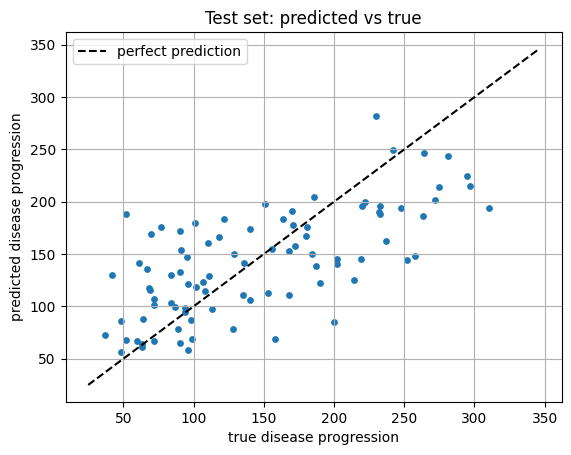

In [50]:
plt.scatter(y_test, y_pred, s=15)
plt.plot([25, 346], [25, 346], color="black", linestyle="--", label="perfect prediction")
plt.xlabel("true disease progression")
plt.ylabel("predicted disease progression")
plt.title("Test set: predicted vs true")
plt.legend()
plt.grid(True)
plt.show()

Points close to the dashed line are good predictions. Medical data is noisy, so the points are spread out,
but the network clearly beats the baseline.

## A.16 Summary

The full recipe for training a neural network with SGD and backpropagation:

1. **Prepare data:** split into train and test, scale the target.
2. **Initialise** the weights with small random numbers.
3. For each **epoch**, shuffle the training data, and for **each example**:
    1. **Forward pass:** compute the prediction $\hat{y}$.
    2. **Loss:** $L = \frac{1}{2}(\hat{y} - y)^2$.
    3. **Backward pass:** compute the gradient for every weight with backpropagation.
    4. **Update:** $w = w - \eta \cdot \text{gradient}$.
4. **Monitor** the training and test loss after each epoch.
5. **Evaluate** on the test set and compare with a baseline.

---
# PART B: Graded Exercises (Session 2)

**Total: 100 marks. Suggested time: 30 minutes.**

| Exercise | Topic | Marks |
|---|---|---|
| Exercise 1 | Forward pass and loss | 30 |
| Exercise 2 | Backpropagation and one SGD step | 35 |
| Exercise 3 | Learning rate experiment | 35 |
| **Total** | | **100** |

### Instructions
- Make sure you have **run all cells of Part A** first. You will use `sigmoid`, `forward`, `backward`, `loss_fn` and `train_network`.
- Write your code only where you see `# YOUR CODE HERE`, and replace every `None` with your answer.
- Do not change the cells that give you the data.
- Before submitting, use **Runtime > Restart and run all** (Colab) to check that your notebook runs without errors.

## Exercise 1: Forward pass and loss (30 marks)

Below is a **tiny network** with 2 inputs, 2 hidden neurons (sigmoid) and 1 output, plus one training example.

**Do not use the `forward` function in parts (a) and (b).** Write the steps yourself with `np.dot` and `sigmoid`.

**(a)** Compute the weighted sums `z1` of the hidden layer and the hidden outputs `a1`. **(10 marks)**

In [51]:
# Given data (do not change)
x = np.array([1.0, 2.0])          # 2 inputs
y = 3.0                           # true target

W1 = np.array([[0.5, -0.5],
               [0.25, 0.75]])     # shape (2, 2)
b1 = np.array([0.0, 0.5])         # shape (2,)
w2 = np.array([1.0, 2.0])         # shape (2,)
b2 = 0.5

In [52]:
z1 = W1 @ x + b1
a1 = np.maximum(0, z1)
print("z1 =", z1)
print("a1 =", a1)

z1 = [-0.5   2.25]
a1 = [0.   2.25]


**(b)** Compute the prediction `y_hat` of the output neuron. **(10 marks)**

In [53]:
y_hat =  w2 @ a1 + b2

print("y_hat =", y_hat)

y_hat = 5.0


**(c)** Compute the loss $L = \frac{1}{2}(\hat{y} - y)^2$ **using the formula** (not `loss_fn`).
Then check your answer: call the `forward` function from Part A with the same weights and print its prediction.
It must be the same as your `y_hat`. **(10 marks)**

In [57]:
L = 0.5 * (y_hat - y) ** 2
print("Loss L =", L)

check_a1, check_y_hat = forward(x, W1, b1, w2, b2)
print("y_hat from forward():", check_y_hat)

Loss L = 2.0
y_hat from forward(): 2.6868417389999264


## Exercise 2: Backpropagation and one SGD step (35 marks)

Use the **same tiny network** and the values `x`, `y`, `a1`, `y_hat`, `w2` from Exercise 1.
Use the table in **A.11** to help you.

**Do not use the `backward` function in parts (a) and (b).** Write each step yourself.

**(a)** Compute the output error `dy`, and the gradients of the output layer `dw2` and `db2`. **(10 marks)**

In [58]:
dy = y_hat - y
dw2 = dy * a1
db2 = dy

print("dy  =", dy)
print("dw2 =", dw2)
print("db2 =", db2)

dy  = 2.0
dw2 = [0.  4.5]
db2 = 2.0


**(b)** Send the error back to the hidden layer: compute `da1`, `dz1`, and the gradients of the hidden layer `dW1` and `db1`. **(15 marks)**

In [59]:
da1 = dy * w2
dz1 = da1 * (a1 > 0)
dW1 = np.outer(dz1, x)
db1 = dz1.copy()

print("da1 =", da1)
print("dz1 =", dz1)
print("dW1 =")
print(dW1)
print("db1 =", db1)

da1 = [2. 4.]
dz1 = [0. 4.]
dW1 =
[[0. 0.]
 [4. 8.]]
db1 = [0. 4.]


**(c)** Do **one SGD update** of all four weights (`W1`, `b1`, `w2`, `b2`) with learning rate **0.5**.
Then run a forward pass with the new weights (you may use `forward` and `loss_fn` here) and print the loss **before** and **after** the update.
Did the loss decrease? **(10 marks)**

In [60]:
learning_rate = 0.5
loss_before = loss_fn(y_hat, y)

W1_new = W1 - learning_rate * dW1
b1_new = b1 - learning_rate * db1
w2_new = w2 - learning_rate * dw2
b2_new = b2 - learning_rate * db2

new_a1 = np.maximum(0, W1_new @ x + b1_new)
new_y_hat = w2_new @ new_a1 + b2_new
loss_after = 0.5 * (new_y_hat - y) ** 2

print("Loss before the update:", loss_before)
print("Loss after the update :", loss_after)

Loss before the update: 2.0
Loss after the update : 6.125


## Exercise 3: Learning rate experiment (35 marks)

Now go back to the **Diabetes dataset** (`X_train`, `y_train_s`, `X_test`, `y_test_s` from Part A)
and study how the **learning rate** changes the training.

**(a)** Use `train_network` to train **three** networks, each with `n_hidden=8` and `epochs=30`,
and learning rates **0.0005**, **0.05** and **2.0**.
Save the list of **test losses** of each network. **(15 marks)**

Hint: `train_network` returns 6 values. You only need the last one, for example:
`W1_a, b1_a, w2_a, b2_a, train_a, test_a = train_network(...)`

In [61]:
test_losses_small = train_network(
    X_train, y_train_s, X_test, y_test_s,
    n_hidden=8, epochs=30, learning_rate=0.0005
)[-1]

test_losses_medium = train_network(
    X_train, y_train_s, X_test, y_test_s,
    n_hidden=8, epochs=30, learning_rate=0.05
)[-1]

test_losses_large = train_network(
    X_train, y_train_s, X_test, y_test_s,
    n_hidden=8, epochs=30, learning_rate=2.0
)[-1]

Epoch 10   train loss = 0.5091   test loss = 0.4487
Epoch 20   train loss = 0.5074   test loss = 0.4465
Epoch 30   train loss = 0.5056   test loss = 0.4454
Epoch 10   train loss = 0.2926   test loss = 0.2574
Epoch 20   train loss = 0.2908   test loss = 0.2673
Epoch 30   train loss = 0.2867   test loss = 0.2922
Epoch 10   train loss = 8678.2935   test loss = 8664.7795
Epoch 20   train loss = 58.2701   test loss = 57.1134
Epoch 30   train loss = 2179.551   test loss = 2172.7498


**(b)** Plot the **three test-loss curves on one figure**. Add a label for each curve, a legend,
axis labels (`epoch` and `test loss`) and a title. **(10 marks)**

Hint: one curve becomes very large. Add `plt.yscale("log")` before `plt.show()` so that all three curves are visible.

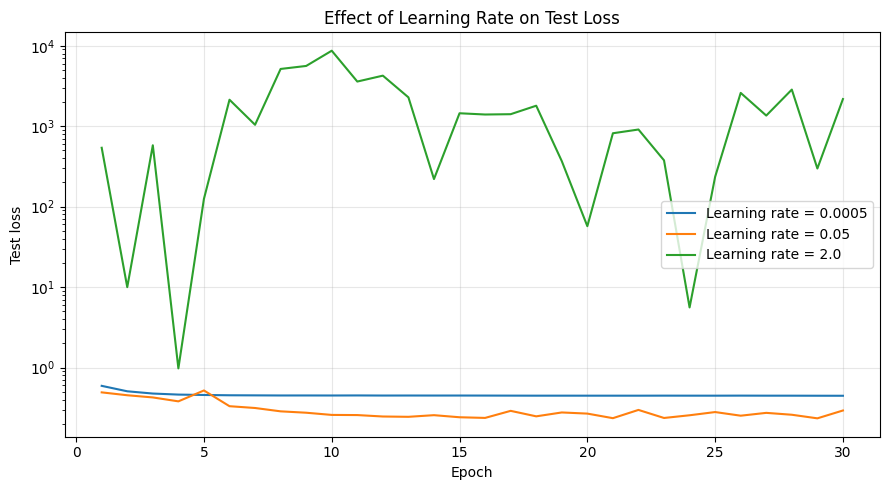

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(test_losses_small) + 1),
    test_losses_small,
    label="Learning rate = 0.0005"
)

plt.plot(
    range(1, len(test_losses_medium) + 1),
    test_losses_medium,
    label="Learning rate = 0.05"
)

plt.plot(
    range(1, len(test_losses_large) + 1),
    test_losses_large,
    label="Learning rate = 2.0"
)

plt.xlabel("Epoch")
plt.ylabel("Test loss")
plt.title("Effect of Learning Rate on Test Loss")
plt.legend()
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**(c)** Answer the questions below in the cell underneath (write 1 to 2 sentences for each). **(10 marks)**

1. Which learning rate gave the **lowest final test loss**? Print or read the last value of each list to support your answer. (4 marks)
2. Describe what happened with the **smallest** learning rate, and explain why. (3 marks)
3. Describe what happened with the **largest** learning rate, and explain why. Use the idea of the step size from A.9. (3 marks)

In [63]:
import numpy as np

rates = [0.0005, 0.05, 2.0]
final_losses = [
    float(test_losses_small[-1]),
    float(test_losses_medium[-1]),
    float(test_losses_large[-1])
]

for rate, loss in zip(rates, final_losses):
    print(f"Learning rate = {rate}: final test loss = {loss:.6g}")

valid_results = [
    (rate, loss)
    for rate, loss in zip(rates, final_losses)
    if np.isfinite(loss)
]

if valid_results:
    best_rate, best_loss = min(valid_results, key=lambda item: item[1])
    print(
        f"\nThe learning rate {best_rate} gave the lowest finite "
        f"final test loss: {best_loss:.6g}."
    )
else:
    print("\nAll three final test losses are non-finite.")

Learning rate = 0.0005: final test loss = 0.445398
Learning rate = 0.05: final test loss = 0.292168
Learning rate = 2.0: final test loss = 2172.75

The learning rate 0.05 gave the lowest finite final test loss: 0.292168.


**Your answers:**

1.

2.

3.